In [50]:
from google.colab import files
uploaded = files.upload()

Saving processed.cleveland.data to processed.cleveland (1).data


In [51]:

print("Heart Disease Prediction Project")
print("Using Machine Learning")
print("Algorithms: Decision Tree and Random Forest")


Heart Disease Prediction Project
Using Machine Learning
Algorithms: Decision Tree and Random Forest


In [52]:

import pandas as pd

# Column names of the Cleveland Heart Disease dataset
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "target"
]

# Read the uploaded dataset
df = pd.read_csv(
    "/content/processed.cleveland.data",
    names=columns,
    na_values="?"
)

# Display first 5 rows
display(df.head())

# Display dataset information
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Dataset shape: (303, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [53]:

# Check missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum())

# Replace missing values with the median of each column
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Check missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

# Display cleaned dataset
display(df.head())

print("\nDataset shape:", df.shape)


Missing values before cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Dataset shape: (303, 14)


In [54]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


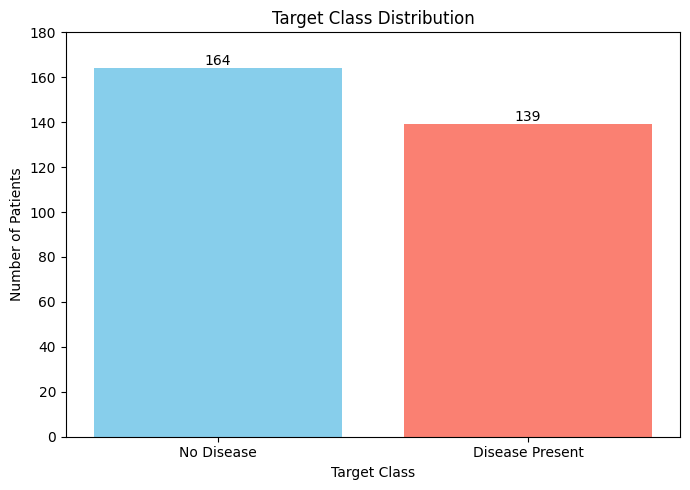

In [55]:
import matplotlib.pyplot as plt

target_counts = df['target'].value_counts()

no_disease = target_counts.get(0, 0)
disease_present = target_counts.drop(labels=[0], errors='ignore').sum()

labels = ['No Disease', 'Disease Present']
counts = [no_disease, disease_present]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, counts, color=['skyblue', 'salmon'])

plt.title('Target Class Distribution')
plt.xlabel('Target Class')
plt.ylabel('Number of Patients')
plt.ylim(0, 180)
plt.bar_label(bars)
plt.tight_layout()
plt.show()

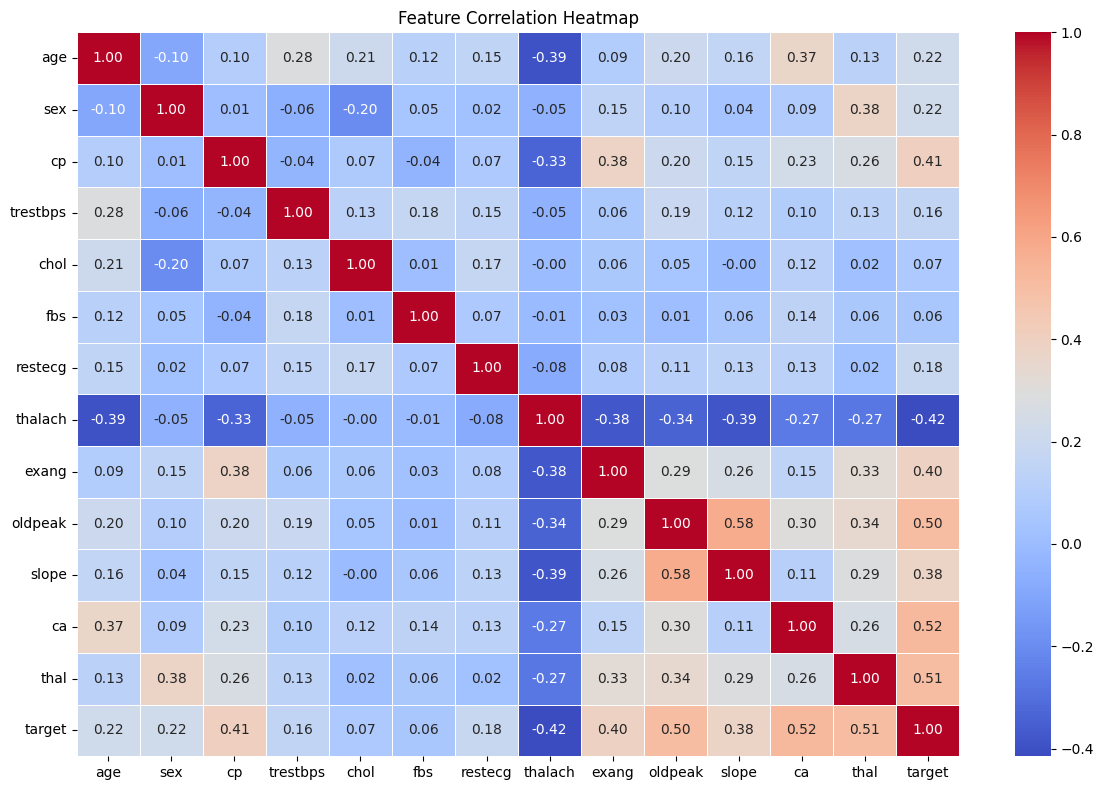

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [57]:
print(df['target'].value_counts().sort_index())

target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [58]:

# Input features
X = df.drop("target", axis=1)

# Convert target into binary classification
y = (df["target"] > 0).astype(int)

print("Input features shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts().rename(
    index={0: "No Disease", 1: "Disease Present"}
))


Input features shape: (303, 13)

Target distribution:
target
No Disease         164
Disease Present    139
Name: count, dtype: int64


In [59]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training input:", X_train.shape)
print("Testing input:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training input: (242, 13)
Testing input: (61, 13)
Training target: (242,)
Testing target: (61,)


In [60]:

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Predict using test data
dt_predictions = dt_model.predict(X_test)

print("Decision Tree model training completed!")
print("First 10 predictions:", dt_predictions[:10])
print("First 10 actual values:", y_test.to_numpy()[:10])


Decision Tree model training completed!
First 10 predictions: [0 1 0 0 0 0 1 0 1 0]
First 10 actual values: [0 0 0 0 0 0 0 0 1 0]


In [61]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
print("Decision Tree Evaluation")
print("-------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, dt_predictions), 3))

print("Precision:",
      round(precision_score(y_test, dt_predictions, zero_division=0), 3))

print("Recall:",
      round(recall_score(y_test, dt_predictions, zero_division=0), 3))

print("F1-score:",
      round(f1_score(y_test, dt_predictions, zero_division=0), 3))

print("\nClassification Report:")
print(classification_report(
    y_test, dt_predictions,
    target_names=["No Disease", "Disease Present"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_predictions))


Decision Tree Evaluation
-------------------------
Accuracy: 0.738
Precision: 0.676
Recall: 0.821
F1-score: 0.742

Classification Report:
                 precision    recall  f1-score   support

     No Disease       0.81      0.67      0.73        33
Disease Present       0.68      0.82      0.74        28

       accuracy                           0.74        61
      macro avg       0.75      0.74      0.74        61
   weighted avg       0.75      0.74      0.74        61

Confusion Matrix:
[[22 11]
 [ 5 23]]


In [62]:

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest model training completed!")
print("First 10 predictions:", rf_predictions[:10])


Random Forest model training completed!
First 10 predictions: [0 1 0 0 0 0 0 0 1 0]


In [63]:

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

# Compare both models
results = []

for name, predictions in [
    ("Decision Tree", dt_predictions),
    ("Random Forest", rf_predictions)
]:
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison = pd.DataFrame(results)

display(comparison.round(3))


,Algorithm,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.738,0.676,0.821,0.742
1,Random Forest,0.885,0.839,0.929,0.881


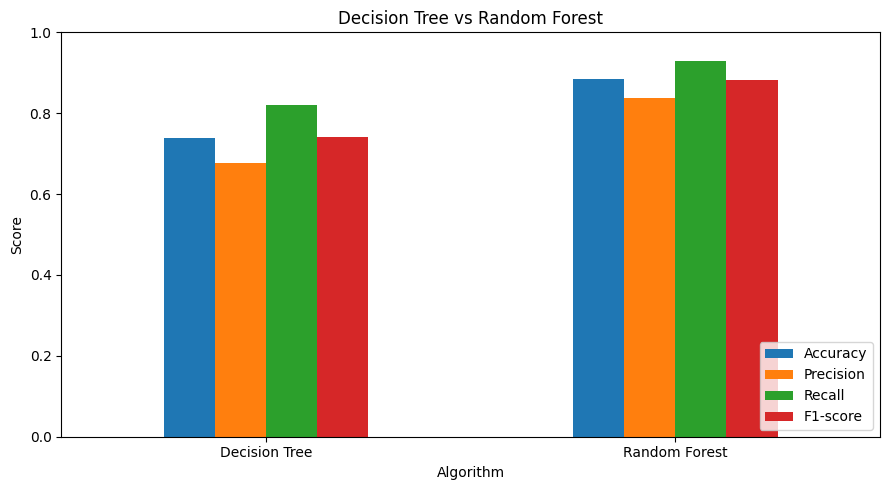

In [64]:

import matplotlib.pyplot as plt

comparison.set_index("Algorithm").plot(
    kind="bar",
    figsize=(9, 5),
    ylim=(0, 1)
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Score")
plt.xlabel("Algorithm")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [65]:

from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)

# Parameters to test
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Create optimization process
grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(X_train, y_train)

# Best optimized model
best_rf = grid_search.best_estimator_
optimized_predictions = best_rf.predict(X_test)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation F1-score:")
print(round(grid_search.best_score_, 3))

print("\nOptimized model test results:")
print("Accuracy:",
      round(accuracy_score(y_test, optimized_predictions), 3))
print("Precision:",
      round(precision_score(y_test, optimized_predictions, zero_division=0), 3))
print("Recall:",
      round(recall_score(y_test, optimized_predictions, zero_division=0), 3))
print("F1-score:",
      round(f1_score(y_test, optimized_predictions, zero_division=0), 3))


Best parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 100}

Best cross-validation F1-score:
0.811

Optimized model test results:
Accuracy: 0.902
Precision: 0.867
Recall: 0.929
F1-score: 0.897


In [66]:

# Compare original and optimized Random Forest

from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

final_results = []

for name, predictions in [
    ("Decision Tree", dt_predictions),
    ("Random Forest", rf_predictions),
    ("Optimized Random Forest", optimized_predictions)
]:
    final_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

final_comparison = pd.DataFrame(final_results)

display(final_comparison.round(3))


,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.738,0.676,0.821,0.742
1,Random Forest,0.885,0.839,0.929,0.881
2,Optimized Random Forest,0.902,0.867,0.929,0.897


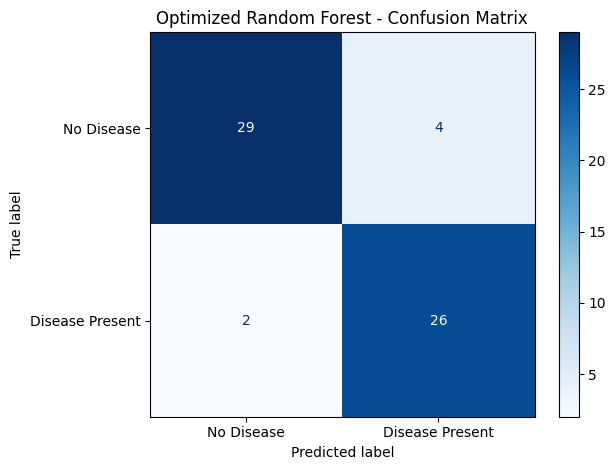

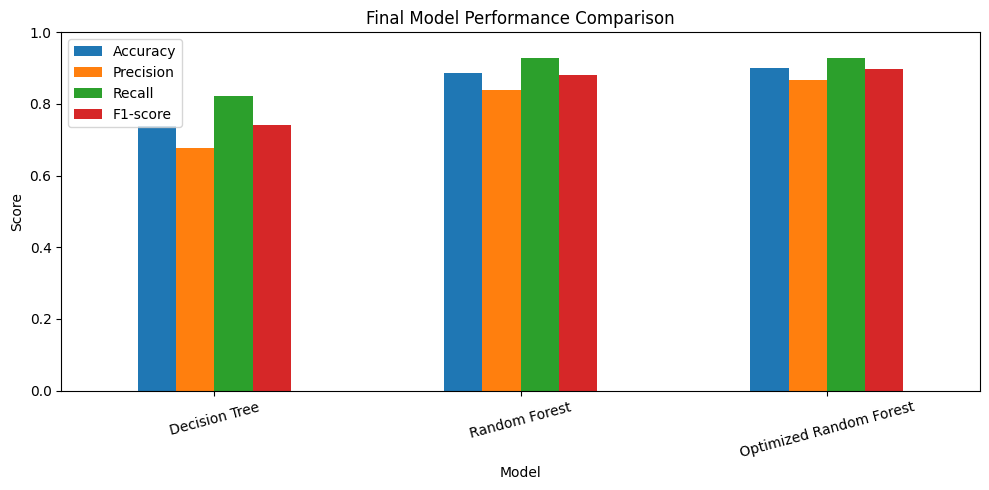

In [67]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix for optimized Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    optimized_predictions,
    display_labels=["No Disease", "Disease Present"],
    cmap="Blues"
)

plt.title("Optimized Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

# Final model comparison graph
final_comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Final Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [68]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("Predictions:", len(optimized_predictions))

X_test shape: (61, 13)
y_test shape: (61,)
Predictions: 61


In [69]:
from sklearn.metrics import classification_report

print("Optimized Random Forest - Classification Report")
print(classification_report(y_test, optimized_predictions,
                            target_names=["No Disease", "Disease Present"]))

Optimized Random Forest - Classification Report
                 precision    recall  f1-score   support

     No Disease       0.94      0.88      0.91        33
Disease Present       0.87      0.93      0.90        28

       accuracy                           0.90        61
      macro avg       0.90      0.90      0.90        61
   weighted avg       0.90      0.90      0.90        61



In [70]:

import joblib
from google.colab import files

# Save the final comparison table
final_comparison.to_csv(
    "heart_disease_model_results.csv",
    index=False
)

# Save the optimized Random Forest model
joblib.dump(
    best_rf,
    "optimized_heart_disease_model.pkl"
)

print("Project results and trained model saved!")

# Download both files
files.download("heart_disease_model_results.csv")
files.download("optimized_heart_disease_model.pkl")


Project results and trained model saved!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>